# 03 — Détection de fuites hors-ligne : IsolationForest vs CUSUM, validés sur BattLeDIM

**Objectif** : construire un détecteur de fuites **non supervisé** (IsolationForest), le comparer à une **référence simple** (CUSUM sur la chute de pression) et mesurer honnêtement les deux sur un benchmark public dont les fuites sont documentées. Chaque méthode doit aussi faire **mieux que des alertes tirées au hasard**.

| | |
|---|---|
| **Entrées** | `data/processed/battledim_flows.parquet` (3 débitmètres), `battledim_pressures.parquet` (33 capteurs de pression), `battledim_leaks.parquet` (dates déclarées), `battledim_leak_flow.parquet` |
| **Sorties** | `models/artifacts/iforest.joblib`, `leak_features.json`, `leak_threshold.json`, `leak_metrics.json` ; expérience MLflow `03_leak_detection_battledim` |
| **Durée** | ~1–2 min |

**Protocole (v3)** : IsolationForest ajusté sur janv.–août 2018 ; seuil calé sur sept.–déc. 2018 sous la contrainte **≤ 1 fausse alerte par semaine** ; **test sur 2019** (19 fuites jamais vues).

**Logique d'alerte (v3)** : variables mesurées par rapport à une **référence glissante de 7 jours** ; alerte si le score dépasse le seuil **k fois sur n heures** (3/4 et 4/6 testés), puis **pause de 72 h** ; après chaque alerte, la référence est **reconstruite** avec les données postérieures (« nouveau normal »), pour ne redéclencher que sur un **nouveau** changement. La même logique s'applique à l'IsolationForest et au CUSUM.

**Critère de réussite** : battre nettement des alertes **régulières** (p < 0,05) avec ≤ 1 fausse alerte par semaine en 2019.

**Évaluation par incident** : une fuite est détectée si une alerte démarre dans les 72 h qui suivent son début déclaré. Toute autre alerte est une **fausse alerte**.

> **BattLeDIM = réseau urbain L-Town (Chypre), données simulées réalistes.** Il s'agit d'un réseau de distribution d'eau potable (782 nœuds, 905 conduites), pas d'un réseau d'irrigation. Nous l'utilisons pour **valider la méthode** sur des fuites documentées : écarts au profil hebdomadaire, résidus entre capteurs voisins, débit nocturne minimal, score d'anomalie lissé, seuil choisi sur la validation.
>
> **Transposition au réseau d'irrigation d'AquaMind** : le modèle ne reçoit que **8 variables agrégées, sans dimension et normalisées** (z-scores robustes). Elles ne dépendent pas du nombre de capteurs et ont un équivalent direct sur la ferme (débit S1 vs plan, pressions des tronçons, déséquilibre du bilan de masse, débit hors irrigation). Voir `farm_mapping` dans `leak_features.json`.

## 1. Imports, chemins et MLflow

In [1]:
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression

EXPERIMENT = "03_leak_detection_battledim"
SEED = 42
np.random.seed(SEED)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "aquamind_core").is_dir())
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("mlflow").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# MLflow : file store local mlruns/ à la racine (équivalent de "file:../mlruns" depuis notebooks/)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)
mlflow.end_run()  # ferme un run resté ouvert par une exécution précédente interrompue
run = mlflow.start_run(run_name=f"{EXPERIMENT}-{time.strftime('%Y%m%d-%H%M%S')}")
T0 = time.perf_counter()
print("Racine :", ROOT)
print("MLflow :", mlflow.get_tracking_uri(), "| run", run.info.run_id)

Racine : c:\Users\ghodh\aquamind
MLflow : file:///c:/Users/ghodh/aquamind/mlruns | run b5cbe828954e40649e1010a46959f0cc


## 2. Chargement et rééchantillonnage horaire

In [2]:
flows = pd.read_parquet(PROCESSED / "battledim_flows.parquet")
pres = pd.read_parquet(PROCESSED / "battledim_pressures.parquet")
leaks = pd.read_parquet(PROCESSED / "battledim_leaks.parquet")
leak_flow = pd.read_parquet(PROCESSED / "battledim_leak_flow.parquet")
print("débits", flows.shape, "| pressions", pres.shape, "| fuites", len(leaks))

# 5 min → 1 h (moyenne) : 17 520 heures, bruit réduit, calcul rapide
flows_h = flows.resample("1h").mean().astype("float64")
pres_h = pres.resample("1h").mean().astype("float64")
idx = pres_h.index
flows_h = flows_h.reindex(idx)
leak_flow_h = leak_flow["leak_flow_m3h"].resample("1h").mean().reindex(idx)

FIT_END = pd.Timestamp("2018-08-31 23:00")
TEST_START = pd.Timestamp("2019-01-01")
period = pd.Series(np.where(idx <= FIT_END, "fit", np.where(idx < TEST_START, "val", "test")), index=idx)
print(period.value_counts().to_dict())
leaks[["link_id", "start", "end", "leak_type", "diameter_m", "repaired", "max_flow_m3h"]]

débits (210240, 3) | pressions (210240, 33) | fuites 33
{'test': 8760, 'fit': 5832, 'val': 2928}


,link_id,start,end,leak_type,diameter_m,repaired,max_flow_m3h
0,p257,2018-01-08 13:30:00,2019-12-31 23:55:00,incipient,0.011843,False,6.870000
1,p461,2018-01-23 04:25:00,2018-04-02 11:40:00,incipient,0.021320,True,30.540001
2,p232,2018-01-31 02:35:00,2018-02-10 09:20:00,incipient,0.020108,True,26.100000
3,p427,2018-02-13 08:25:00,2019-12-31 23:55:00,incipient,0.009073,False,5.110000
4,p673,2018-03-05 15:45:00,2018-03-23 10:25:00,abrupt,0.022916,True,28.420000
5,p628,2018-05-02 14:55:00,2018-05-29 21:20:00,incipient,0.022318,True,35.380001
6,p538,2018-05-18 08:35:00,2018-06-02 06:05:00,abrupt,0.021731,True,32.840000
7,p866,2018-06-01 09:05:00,2018-06-12 03:00:00,abrupt,0.018108,True,20.570000
8,p31,2018-06-28 10:35:00,2018-08-12 17:30:00,incipient,0.016389,True,16.209999
9,p654,2018-07-05 03:40:00,2019-12-31 23:55:00,incipient,0.008774,False,5.490000


## 3. Étiquettes à partir des dates déclarées (`start` / `end`)

Avec l'étiquette stricte (« une fuite déclarée est active »), **≈ 98 % des heures de 2018 et 100 % de celles de 2019 sont positives**. Plusieurs fuites progressives ne sont jamais réparées, et il n'existe aucune heure sans fuite après le 8 janvier 2018. Une alarme permanente obtiendrait alors un F1 ≈ 0,99, ce qui ne mesure rien.

On garde donc les **dates déclarées**, mais on évalue ce qui compte en exploitation : **l'apparition d'une nouvelle fuite**.
- `y_onset` = 1 pendant les **72 h** qui suivent le début déclaré (`start`), tronquées à la fin déclarée (`end`). On l'utilise pour exclure ces heures de l'entraînement et pour les graphiques.
- **Évaluation (section 6)** : une fuite est *détectée* si une **nouvelle** alerte démarre entre `start` et `min(end, start + 72 h)`. Délai = heure de l'alerte − heure de début. On ne calcule plus de F1 point par point : avec des fuites qui se chevauchent pendant des mois, il récompense une alarme allumée en permanence.

In [3]:
ONSET_H = 72
EVENT_DAYS = 14  # tolérance de l'ancienne évaluation, gardée pour event_window (non utilisé en v3)
y_active = pd.Series(0, index=idx, dtype="int8")
y_onset = pd.Series(0, index=idx, dtype="int8")
event_window = pd.Series(False, index=idx)
for r in leaks.itertuples():
    start_h = r.start.floor("h")
    y_active[(idx >= start_h) & (idx <= r.end)] = 1
    y_onset[(idx >= start_h) & (idx <= min(r.end, r.start + pd.Timedelta(hours=ONSET_H)))] = 1
    event_window[(idx >= start_h) & (idx <= min(r.end, r.start + pd.Timedelta(days=EVENT_DAYS)))] = True

prevalence = pd.DataFrame({
    "étiquette stricte : fuite active (%)": y_active.groupby(idx.year).mean() * 100,
    f"nouvelle fuite, {ONSET_H} h (%)": y_onset.groupby(idx.year).mean() * 100,
}).round(1)
prevalence

,étiquette stricte : fuite active (%),"nouvelle fuite, 72 h (%)"
timestamp,,
2018,97.9,11.7
2019,100.0,15.8


## 4. Variables avec une référence glissante de 7 jours

Toutes les variables sont des **écarts à une référence récente**, calculée uniquement avec le passé :

- **Référence** = médiane des valeurs **à la même heure** sur les **7 jours précédents** (t − 24 h, …, t − 7 × 24 h). Le cycle journalier est respecté et la référence suit l'évolution du réseau : une fuite ancienne non réparée devient « normale » au bout de quelques jours.
- **Pressions (33 capteurs)** : écart de chaque capteur à sa référence, en z-score robuste.
- **Résidus entre voisins** : chaque capteur est prédit par ses 3 voisins les plus corrélés (régression ajustée sur janv.–août 2018). On mesure l'écart du résidu à **sa** référence de 7 jours.
- **Débit d'entrée** : écart à la référence ; moyenne et écart-type sur 24 h.
- **Débit nocturne minimal** (2h–4h) : écart à la médiane des 7 nuits précédentes.

Les échelles des z-scores (1,4826 × MAD) sont des **constantes de normalisation** calculées une fois sur janv.–août 2018. Ce ne sont pas des profils de référence.

**« Nouveau normal » après une alerte** : après une alerte à l'instant *a*, la référence est **reconstruite uniquement avec les données postérieures à *a*** (2 jours au minimum, car la pause dure 72 h). Une fuite non réparée entre donc dans la référence, et seul un **nouveau changement** peut redéclencher. Pour cela, on précalcule les variables avec des références de **m = 3 à 7 jours**. Au temps t, on utilise m = min(7, nombre de jours écoulés depuis la dernière alerte).

In [4]:
M_MIN, M_MAX = 3, 7   # âge minimal de la référence après une alerte (= pause de 72 h) ; référence normale = 7 jours


def same_hour_reference(x: pd.DataFrame, days: int) -> pd.DataFrame:
    """Médiane des valeurs à la même heure sur les `days` jours précédents (passé uniquement)."""
    stack = np.stack([x.shift(24 * k).to_numpy() for k in range(1, days + 1)])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)  # tranches tout-NaN au tout début
        return pd.DataFrame(np.nanmedian(stack, axis=0), index=x.index, columns=x.columns)


def robust_scale(x, ref_mask: pd.Series):
    """Échelle robuste 1,4826 × MAD calculée sur la période de référence (constante de normalisation)."""
    ref = x[ref_mask]
    scale = 1.4826 * (ref - ref.median()).abs().median()
    if isinstance(scale, pd.Series):
        return scale.replace(0, np.nan).fillna(1.0)
    return scale if np.isfinite(scale) and scale > 0 else 1.0


REF = period.eq("fit") & y_onset.eq(0)
fit_mask = period.eq("fit")

# Résidus capteur ~ 3 voisins les plus corrélés (modèle linéaire ajusté sur janv.–août 2018)
K_NEIGHBOURS = 3
corr = pres_h[fit_mask].corr()
neighbours = {s: corr[s].drop(s).nlargest(K_NEIGHBOURS).index.tolist() for s in pres_h.columns}
resid = pd.DataFrame(np.nan, index=idx, columns=pres_h.columns)
for s, nb in neighbours.items():
    ref = pres_h.loc[fit_mask, [s, *nb]].dropna()
    lr = LinearRegression().fit(ref[nb], ref[s])
    ok = pres_h[[s, *nb]].notna().all(axis=1)
    resid.loc[ok, s] = pres_h.loc[ok, s] - lr.predict(pres_h.loc[ok, nb])

q = flows_h.sum(axis=1, min_count=flows_h.shape[1]).to_frame("q_total")
night = q["q_total"][q.index.hour.isin([2, 3, 4])].resample("D").min()


def build_features(m: int, scales: dict | None = None) -> tuple[pd.DataFrame, dict]:
    """Les 8 variables avec une référence de m jours. `scales` = échelles figées (calculées pour m = 7)."""
    p_dev = pres_h - same_hour_reference(pres_h, m)
    r_dev = resid - same_hour_reference(resid, m)
    q_dev = (q - same_hour_reference(q, m))["q_total"]
    nd = night - night.rolling(m, min_periods=min(m, 3)).median().shift(1)
    nd.index = nd.index + pd.Timedelta(hours=5)   # connu à partir de 5h
    nd_h = nd.reindex(idx, method="ffill")
    if scales is None:
        scales = {"p": robust_scale(p_dev, REF), "r": robust_scale(r_dev, REF),
                  "q": robust_scale(q_dev, REF), "night": robust_scale(nd_h, REF)}
    pz, rz = p_dev / scales["p"], r_dev / scales["r"]
    qz, nz = q_dev / scales["q"], nd_h / scales["night"]
    f = pd.DataFrame(index=idx)
    f["p_dev_mean"] = pz.mean(axis=1)
    f["p_dev_min"] = pz.min(axis=1)
    f["p_frac_low"] = (pz < -2).mean(axis=1).where(pz.notna().all(axis=1))
    f["p_resid_absmax"] = rz.abs().max(axis=1)
    f["q_dev"] = qz
    f["q_dev_24h"] = qz.rolling(24, min_periods=12).mean()
    f["q_night_dev"] = nz
    f["q_std_24h"] = qz.rolling(24, min_periods=12).std()
    return f, scales


t_feat = time.perf_counter()
feats_by_m, SCALES = {}, None
feats_by_m[M_MAX], SCALES = build_features(M_MAX)
for m in range(M_MIN, M_MAX):
    feats_by_m[m], _ = build_features(m, SCALES)
feats = feats_by_m[M_MAX]
FEATURES = list(feats.columns)
valid = feats.notna().all(axis=1)
print(f"{len(FEATURES)} variables × {len(feats_by_m)} références (m = {M_MIN}…{M_MAX} jours) "
      f"en {time.perf_counter() - t_feat:.1f} s ; heures valides : {int(valid.sum())} / {len(idx)}")
feats[valid].describe().T.round(3)

8 variables × 5 références (m = 3…7 jours) en 1.5 s ; heures valides : 17443 / 17520


,count,mean,std,min,25%,50%,75%,max
p_dev_mean,17443.0,0.210,2.177,-7.225,-0.808,-0.056,0.930,12.151
p_dev_min,17443.0,-2.342,4.598,-62.183,-3.379,-1.339,-0.339,5.070
p_frac_low,17443.0,0.115,0.255,0.000,0.000,0.000,0.091,1.000
p_resid_absmax,17443.0,8.501,14.139,0.649,2.224,3.951,8.089,107.330
q_dev,17443.0,-0.448,2.997,-14.326,-0.946,0.055,0.700,9.589
q_dev_24h,17443.0,-0.448,1.331,-5.542,-1.350,-0.282,0.491,3.688
q_night_dev,17443.0,-0.097,1.195,-3.363,-0.581,0.041,0.488,3.013
q_std_24h,17443.0,2.409,1.315,0.253,1.409,2.144,3.269,7.107


### Les variables séparent-elles les fenêtres de nouvelle fuite du reste ? (validation 2018, référence 7 jours)

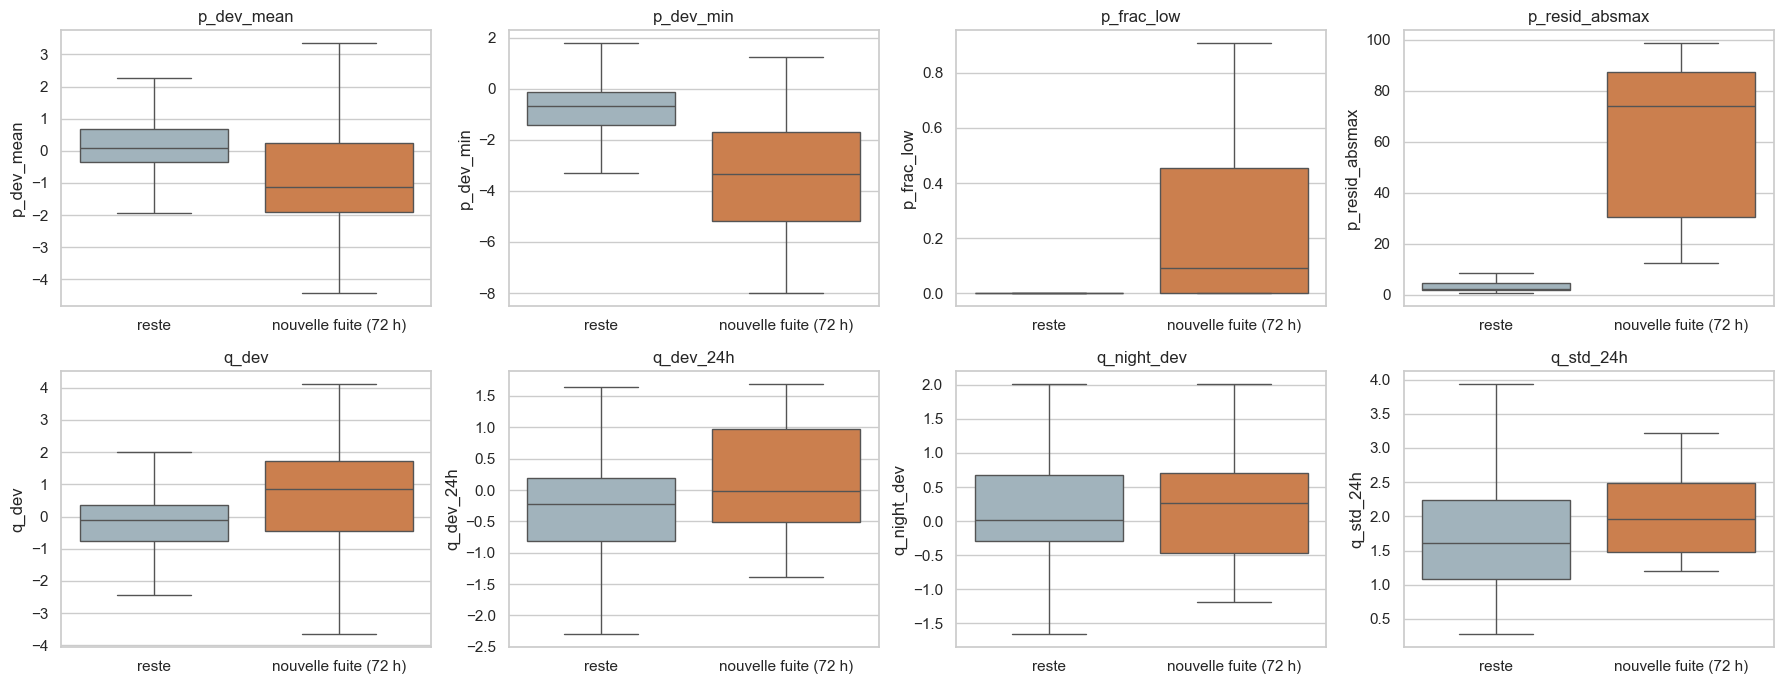

In [5]:
view = feats[valid & period.eq("val")].assign(fenetre=np.where(y_onset[valid & period.eq("val")] == 1,
                                                               "nouvelle fuite (72 h)", "reste"))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=view, x="fenetre", y=col, ax=ax, showfliers=False,
                hue="fenetre", palette={"nouvelle fuite (72 h)": "#e07b39", "reste": "#9db4c0"}, legend=False)
    ax.set_xlabel("")
    ax.set_title(col)
fig.tight_layout()
mlflow.log_figure(fig, "fig_features_val.png")
plt.show()

## 5. IsolationForest (même algorithme) et CUSUM (référence simple)

- **IsolationForest** : ajusté sur janv.–août 2018 hors fenêtres de nouvelle fuite, avec les variables à référence de 7 jours. Il est ensuite appliqué aux variables de chaque référence m. Score = −`score_samples`, lissé sur 6 h.
- **CUSUM** sur la chute moyenne de pression x_t = −`p_dev_mean`, avec k = 0,5 : S_t = max(0, S_{t−1} + x_t − k). Il repart de 0 après chaque alerte (nouveau normal).

In [6]:
SMOOTH_H = 6
CUSUM_K = 0.5
IF_PARAMS = dict(n_estimators=300, max_samples=512, contamination="auto", random_state=SEED, n_jobs=-1)
train_rows = valid & period.eq("fit") & y_onset.eq(0)
iforest = IsolationForest(**IF_PARAMS)
iforest.fit(feats.loc[train_rows, FEATURES].to_numpy())  # numpy : pas de dépendance aux noms de colonnes
print("Lignes d'entraînement :", int(train_rows.sum()))

if_score_by_m, cusum_x_by_m = {}, {}
for m, f in feats_by_m.items():
    raw = np.full(len(idx), np.nan)
    ok = f.notna().all(axis=1).to_numpy() & valid.to_numpy()
    raw[ok] = -iforest.score_samples(f.loc[ok, FEATURES].to_numpy())
    if_score_by_m[m] = pd.Series(raw, index=idx).rolling(SMOOTH_H, min_periods=1).mean().to_numpy(copy=True)
    if_score_by_m[m][~valid.to_numpy()] = np.nan
    cusum_x_by_m[m] = np.where(valid.to_numpy(), -f["p_dev_mean"].to_numpy(), np.nan)

mlflow.log_params({**{f"if_{k}": v for k, v in IF_PARAMS.items()}, "smoothing_hours": SMOOTH_H,
                   "cusum_k": CUSUM_K, "reference_days": M_MAX, "reset_min_days": M_MIN,
                   "onset_hours": ONSET_H, "n_features": len(FEATURES), "neighbours": K_NEIGHBOURS,
                   "train_rows": int(train_rows.sum())})
pd.DataFrame({"IF score (réf. 7 j)": if_score_by_m[M_MAX], "chute de pression x (réf. 7 j)": cusum_x_by_m[M_MAX]},
             index=idx)[valid].describe().T.round(3)

Lignes d'entraînement : 4879


,count,mean,std,min,25%,50%,75%,max
IF score (réf. 7 j),17443.0,0.444,0.076,0.342,0.378,0.425,0.495,0.748
chute de pression x (réf. 7 j),17443.0,-0.210,2.177,-12.151,-0.930,0.056,0.808,7.225


## 6. Logique d'alerte (identique pour les deux méthodes)

1. **Persistance** : alerte si le score dépasse le seuil **k fois sur les n dernières heures** (on teste 3/4 et 4/6).
2. **Pause de 72 h** après chaque alerte (même incident).
3. **Nouveau normal** : après l'alerte, la référence est reconstruite avec les seules données postérieures (variables à m = min(7, jours depuis l'alerte) jours ; CUSUM remis à 0).
4. **Seuil par contrainte** sur la **validation (sept.–déc. 2018)** : le seuil **le plus bas** tel que tous les seuils au-dessus donnent **≤ 1 fausse alerte par semaine**. Il ne dépend pas des 2 seules fuites de la validation.

**Évaluation 2019** : une fuite est détectée si une alerte démarre dans les 72 h suivant son début déclaré ; toute autre alerte est fausse. Deux références sont tirées 2 000 fois avec le **même nombre d'alertes** :
- **aléatoires** : instants tirés uniformément ;
- **régulières** : une alerte toutes les T heures, avec un décalage aléatoire. C'est la référence la plus exigeante, car elle couvre les fenêtres de 72 h sans trou.

**Critère de réussite** : battre nettement les alertes régulières (p < 0,05) **et** ≤ 1 fausse alerte par semaine sur 2019.

In [7]:
REFRACTORY_H = 72
DETECT_H = 72
FA_BUDGET_PER_WEEK = 1.0
KN_CONFIGS = [(3, 4), (4, 6)]
N_SIM = 2000

w_end = pd.concat([leaks["end"], leaks["start"] + pd.Timedelta(hours=DETECT_H)], axis=1).min(axis=1)
windows = pd.DataFrame({"link_id": leaks["link_id"], "type": leaks["leak_type"], "start": leaks["start"],
                        "w_start": leaks["start"].dt.floor("h"), "w_end": w_end})
N_H = len(idx)


def k_of_n(above: np.ndarray, k: int, n: int) -> np.ndarray:
    """True à l'heure t si au moins k des n dernières heures (t incluse) sont au-dessus du seuil."""
    c = np.convolve(above.astype(int), np.ones(n, dtype=int), mode="full")[: len(above)]
    return c >= k


def above(x: np.ndarray, thr: float) -> np.ndarray:
    return np.nan_to_num(x, nan=-np.inf) > thr


def alerts_if(score_by_m: dict, thr: float, k: int, n: int) -> pd.DatetimeIndex:
    """Alertes IsolationForest : persistance k/n + pause + référence reconstruite après chaque alerte."""
    hit7 = k_of_n(above(score_by_m[M_MAX], thr), k, n)
    alerts, a = [], None
    while True:
        nxt = None
        if a is None:
            start = 0
        else:
            lo, hi = a + REFRACTORY_H, min(a + 24 * M_MAX, N_H)
            if lo < hi:  # zone où la référence est encore « jeune » (m < 7 jours)
                tt = np.arange(lo, hi)
                mm = np.clip((tt - a) // 24, M_MIN, M_MAX)
                sc = np.array([score_by_m[m][t] for m, t in zip(mm, tt)])
                c = np.flatnonzero(k_of_n(above(sc, thr), k, n))
                if c.size:
                    nxt = lo + int(c[0])
            start = max(lo, hi)
        if nxt is None:
            c = np.flatnonzero(hit7[start:])
            if not c.size:
                break
            nxt = start + int(c[0])
        alerts.append(nxt)
        a = nxt
    return idx[alerts]


def alerts_cusum(x_by_m: dict, h: float, k: int, n: int) -> pd.DatetimeIndex:
    """Alertes CUSUM : même logique (persistance k/n, pause, remise à zéro = nouveau normal)."""
    xs = {m: v.tolist() for m, v in x_by_m.items()}
    alerts, a, s, hist = [], None, 0.0, []
    for t in range(N_H):
        if a is not None and t < a + REFRACTORY_H:
            continue
        m = M_MAX if a is None else min(M_MAX, (t - a) // 24)
        x = xs[m][t]
        if x != x:  # NaN
            continue
        s = max(0.0, s + x - CUSUM_K)
        hist.append(s > h)
        if len(hist) > n:
            hist.pop(0)
        if sum(hist) >= k:
            alerts.append(t)
            a, s, hist = t, 0.0, []
    return idx[alerts]


def period_hours(name: str) -> pd.DatetimeIndex:
    return idx[(valid & period.eq(name)).to_numpy()]


def evaluate_alerts(alerts: pd.DatetimeIndex, name: str) -> tuple[dict, pd.DataFrame]:
    hours = period_hours(name)
    p0, p1 = hours.min(), hours.max()
    a = alerts[(alerts >= p0) & (alerts <= p1)]
    in_window = np.zeros(len(a), dtype=bool)
    for w in windows.itertuples():
        in_window |= np.asarray((a >= w.w_start) & (a <= w.w_end))
    rows = []
    for w in windows[(windows["start"] >= p0) & (windows["start"] <= p1)].itertuples():
        hits = a[(a >= w.w_start) & (a <= w.w_end)]
        rows.append({"link_id": w.link_id, "type": w.type, "début": w.start, "détectée": len(hits) > 0,
                     "délai (h)": (hits[0] - w.w_start).total_seconds() / 3600 if len(hits) else np.nan})
    ev = pd.DataFrame(rows, columns=["link_id", "type", "début", "détectée", "délai (h)"])
    n_false = int((~in_window).sum())
    det = ev["détectée"]
    return {
        "n_leaks": int(len(ev)), "detected": int(det.sum()),
        "detected_abrupt": int(det[ev["type"] == "abrupt"].sum()), "n_abrupt": int((ev["type"] == "abrupt").sum()),
        "detected_incipient": int(det[ev["type"] == "incipient"].sum()),
        "n_incipient": int((ev["type"] == "incipient").sum()),
        "median_delay_h": float(ev["délai (h)"].median()) if det.any() else float("nan"),
        "n_alerts": int(len(a)), "false_alerts": n_false, "fa_per_week": n_false / (len(hours) / 168),
        "alert_precision": (len(a) - n_false) / len(a) if len(a) else float("nan"),
    }, ev


def calibrate(make_alerts, cands: np.ndarray) -> tuple[float, pd.DataFrame]:
    """Seuil le plus bas tel que tous les seuils supérieurs respectent le budget de fausses alertes (validation)."""
    rows = [{"threshold": float(t), **evaluate_alerts(make_alerts(t), "val")[0]} for t in np.sort(cands)]
    grid = pd.DataFrame(rows)
    chosen = float(grid["threshold"].max())
    for thr, fa in zip(grid["threshold"][::-1], grid["fa_per_week"][::-1]):
        if fa > FA_BUDGET_PER_WEEK:
            break
        chosen = float(thr)
    return chosen, grid


def baseline(n_alerts: int, kind: str, name: str = "test") -> np.ndarray:
    """Détections obtenues par n_alerts alertes « aléatoires » ou « régulières » (N_SIM tirages)."""
    rng = np.random.default_rng(SEED)
    hours = period_hours(name)
    pos = hours.to_numpy().astype("datetime64[ns]").astype(np.int64)
    ev = windows[(windows["start"] >= hours.min()) & (windows["start"] <= hours.max())]
    ws = ev["w_start"].to_numpy().astype("datetime64[ns]").astype(np.int64)
    we = ev["w_end"].to_numpy().astype("datetime64[ns]").astype(np.int64)
    out = np.zeros(N_SIM)
    if n_alerts == 0:
        return out
    period_h = len(pos) / n_alerts
    for i in range(N_SIM):
        if kind == "aléatoires":
            r = np.sort(rng.choice(pos, size=min(n_alerts, len(pos)), replace=False))
        else:
            r = pos[(rng.uniform(0, period_h) + period_h * np.arange(n_alerts)).astype(int).clip(0, len(pos) - 1)]
        out[i] = (np.searchsorted(r, we, side="right") > np.searchsorted(r, ws, side="left")).sum()
    return out


val_mask_np = (valid & period.eq("val")).to_numpy()
CANDS = {
    "IsolationForest": np.unique(np.nanquantile(if_score_by_m[M_MAX][val_mask_np], np.linspace(0.5, 0.999, 120))),
}
plain_cusum = np.zeros(N_H)
s_t = 0.0
for i, x_i in enumerate(np.nan_to_num(cusum_x_by_m[M_MAX], nan=0.0)):
    s_t = max(0.0, s_t + x_i - CUSUM_K)
    plain_cusum[i] = s_t
CANDS["CUSUM"] = np.geomspace(0.5, max(1.0, float(np.nanmax(plain_cusum[val_mask_np]))), 120)
MAKERS = {
    "IsolationForest": lambda thr, k, n: alerts_if(if_score_by_m, thr, k, n),
    "CUSUM": lambda thr, k, n: alerts_cusum(cusum_x_by_m, thr, k, n),
}

results, events, thresholds, alert_sets = {}, {}, {}, {}
for method, maker in MAKERS.items():
    for k, n in KN_CONFIGS:
        key = f"{method} {k}/{n}"
        t0 = time.perf_counter()
        thr, _ = calibrate(lambda t, mk=maker, k=k, n=n: mk(t, k, n), CANDS[method])
        al = maker(thr, k, n)
        val_m, _ = evaluate_alerts(al, "val")
        test_m, test_ev = evaluate_alerts(al, "test")
        for kind in ("aléatoires", "régulières"):
            b = baseline(test_m["n_alerts"], kind)
            test_m[f"{kind}_mean"] = float(b.mean())
            test_m[f"{kind}_p95"] = float(np.quantile(b, 0.95))
            test_m[f"p_vs_{kind}"] = float((b >= test_m["detected"]).mean())
        test_m["success"] = bool(test_m["p_vs_régulières"] < 0.05 and test_m["fa_per_week"] <= FA_BUDGET_PER_WEEK)
        results[key], events[key], thresholds[key], alert_sets[key] = {"val": val_m, "test": test_m}, test_ev, thr, al
        print(f"{key:20s} seuil {thr:9.4f} | val : {val_m['fa_per_week']:.2f} FA/sem., {val_m['detected']}/{val_m['n_leaks']} "
              f"| {time.perf_counter() - t0:.1f} s")

IsolationForest 3/4  seuil    0.4558 | val : 0.98 FA/sem., 1/2 | 1.9 s
IsolationForest 4/6  seuil    0.4540 | val : 0.98 FA/sem., 2/2 | 1.9 s
CUSUM 3/4            seuil    5.8531 | val : 0.98 FA/sem., 2/2 | 3.3 s
CUSUM 4/6            seuil    5.0922 | val : 0.80 FA/sem., 2/2 | 3.8 s


## 7. Résultats sur 2019 (19 fuites jamais vues)

In [8]:
def row(key: str) -> dict:
    m = results[key]["test"]
    return {
        "config": key, "seuil": round(thresholds[key], 4),
        "détectées /19": m["detected"], "brusques /9": m["detected_abrupt"], "progressives /10": m["detected_incipient"],
        "délai médian (h)": round(m["median_delay_h"], 1), "alertes": m["n_alerts"],
        "FA / sem.": round(m["fa_per_week"], 2), "précision alertes": round(m["alert_precision"], 2),
        "aléatoires (moy.)": round(m["aléatoires_mean"], 1), "p vs aléatoires": round(m["p_vs_aléatoires"], 3),
        "régulières (moy.)": round(m["régulières_mean"], 1), "régulières (p95)": m["régulières_p95"],
        "p vs régulières": round(m["p_vs_régulières"], 3), "critère atteint": m["success"],
    }


table = pd.DataFrame([row(k) for k in results]).set_index("config")
display(table.T)

successes = [k for k in results if results[k]["test"]["success"]]
BEST = max(results, key=lambda k: (results[k]["test"]["success"], results[k]["test"]["detected"]
                                   - results[k]["test"]["régulières_mean"], -results[k]["test"]["fa_per_week"]))
CRITERION_MET = bool(successes)
print("\nCritère : battre nettement les alertes régulières (p < 0,05) avec ≤ 1 fausse alerte/semaine en 2019")
for k in results:
    m = results[k]["test"]
    print(f"  {k:20s} {m['detected']:2d}/19 vs régulières {m['régulières_mean']:.1f} (p = {m['p_vs_régulières']:.3f}), "
          f"{m['fa_per_week']:.2f} FA/sem. → {'ATTEINT' if m['success'] else 'non atteint'}")
print(f"\nMeilleure configuration : {BEST}")
print("→ CRITÈRE ATTEINT" if CRITERION_MET else
      "→ CRITÈRE NON ATTEINT : aucune configuration ne bat nettement des alertes régulières. "
      "On garde l'architecture hybride (bilan de masse + River) pour alerter.")

config,IsolationForest 3/4,IsolationForest 4/6,CUSUM 3/4,CUSUM 4/6
seuil,0.4558,0.454,5.8531,5.0922
détectées /19,18,18,14,14
brusques /9,9,9,7,7
progressives /10,9,9,7,7
délai médian (h),44.5,25.0,37.0,32.0
alertes,105,102,86,85
FA / sem.,1.67,1.61,1.38,1.36
précision alertes,0.17,0.18,0.16,0.16
aléatoires (moy.),11.1,10.9,9.8,9.7
p vs aléatoires,0.001,0.0,0.033,0.029



Critère : battre nettement les alertes régulières (p < 0,05) avec ≤ 1 fausse alerte/semaine en 2019
  IsolationForest 3/4  18/19 vs régulières 16.7 (p = 0.267), 1.67 FA/sem. → non atteint
  IsolationForest 4/6  18/19 vs régulières 16.2 (p = 0.289), 1.61 FA/sem. → non atteint
  CUSUM 3/4            14/19 vs régulières 13.6 (p = 0.416), 1.38 FA/sem. → non atteint
  CUSUM 4/6            14/19 vs régulières 13.4 (p = 0.544), 1.36 FA/sem. → non atteint

Meilleure configuration : IsolationForest 4/6
→ CRITÈRE NON ATTEINT : aucune configuration ne bat nettement des alertes régulières. On garde l'architecture hybride (bilan de masse + River) pour alerter.


In [9]:
best_if = max([k for k in results if k.startswith("IsolationForest")],
              key=lambda k: results[k]["test"]["detected"] - results[k]["test"]["régulières_mean"])
best_cu = max([k for k in results if k.startswith("CUSUM")],
              key=lambda k: results[k]["test"]["detected"] - results[k]["test"]["régulières_mean"])
per_leak = events[best_if][["link_id", "type", "début"]].copy()
for key in (best_if, best_cu):
    per_leak[f"{key} — détectée"] = events[key]["détectée"].to_numpy()
    per_leak[f"{key} — délai (h)"] = events[key]["délai (h)"].round(1).to_numpy()
print("Fuites 2019, une par ligne (fenêtre de détection : 72 h après le début déclaré)")
per_leak

Fuites 2019, une par ligne (fenêtre de détection : 72 h après le début déclaré)


,link_id,type,début,IsolationForest 4/6 — détectée,IsolationForest 4/6 — délai (h),CUSUM 4/6 — détectée,CUSUM 4/6 — délai (h)
0,p523,abrupt,2019-01-15 23:00:00,True,5.0,True,11.0
1,p827,abrupt,2019-01-24 18:30:00,True,3.0,False,NaN
2,p280,abrupt,2019-02-10 13:05:00,True,6.0,True,20.0
3,p653,incipient,2019-03-03 13:10:00,True,46.0,True,45.0
4,p710,abrupt,2019-03-24 14:15:00,True,66.0,True,46.0
5,p514,abrupt,2019-04-02 20:40:00,True,17.0,True,71.0
6,p331,abrupt,2019-04-20 10:10:00,True,4.0,True,10.0
7,p193,incipient,2019-05-19 10:40:00,True,66.0,True,48.0
8,p277,incipient,2019-05-30 21:55:00,True,26.0,False,NaN
9,p142,abrupt,2019-06-12 19:55:00,True,24.0,True,44.0


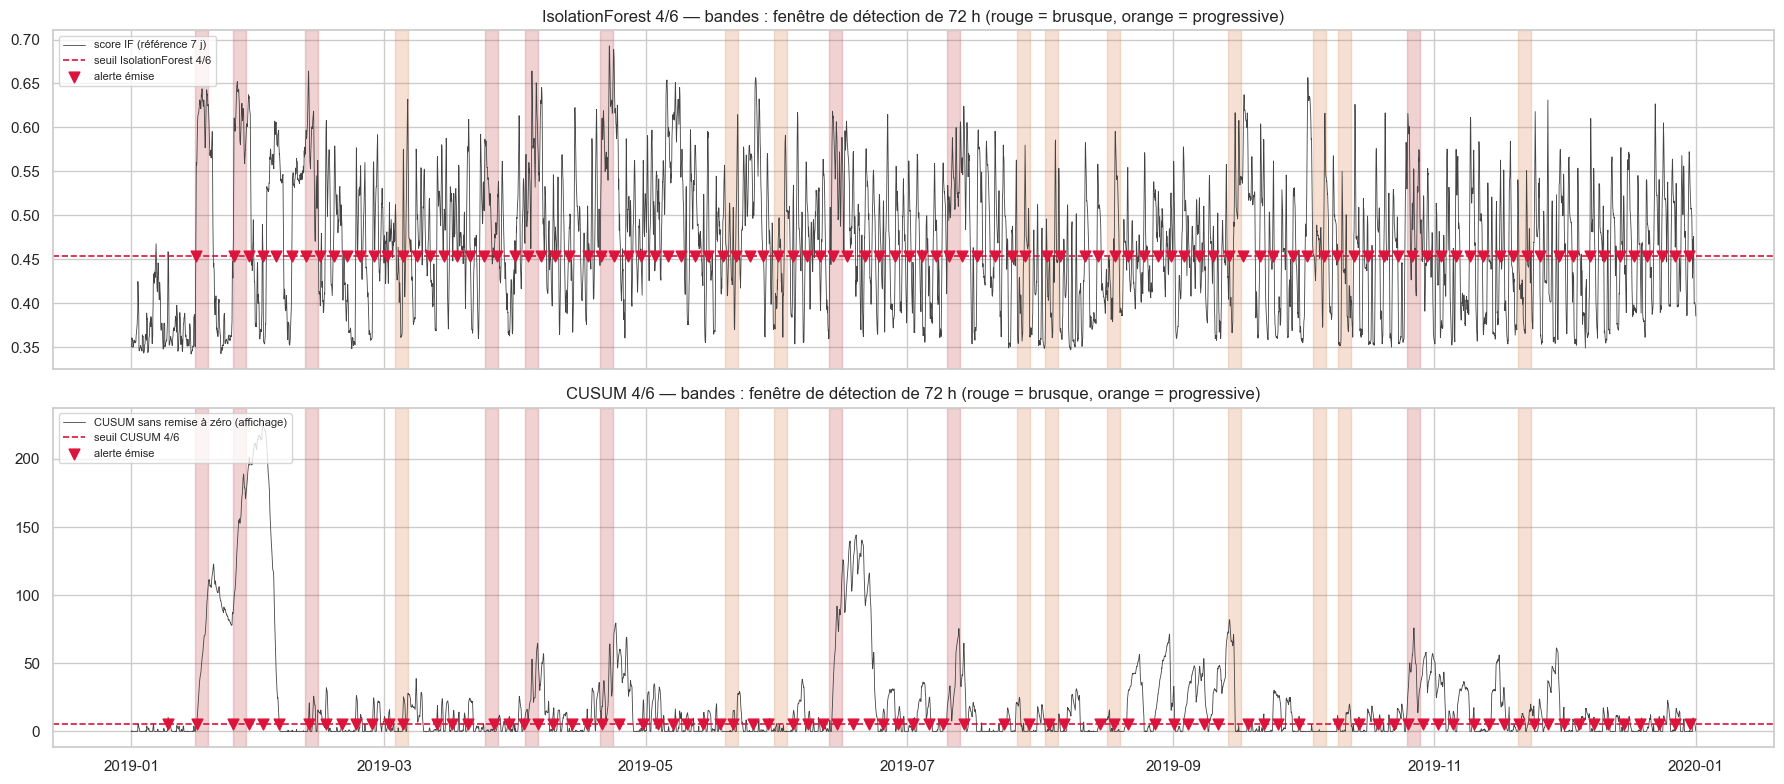

Alertes par mois (2019)


,IsolationForest 3/4,IsolationForest 4/6,CUSUM 3/4,CUSUM 4/6,nouvelles fuites,% temps IF > seuil
timestamp,,,,,,
2019-01,5,4,5,5,2.0,29.0
2019-02,8,8,6,6,1.0,65.2
2019-03,10,10,8,7,2.0,64.2
2019-04,9,9,8,8,2.0,73.3
2019-05,10,10,7,8,2.0,73.1
2019-06,9,8,8,8,1.0,66.1
2019-07,10,9,6,6,2.0,56.0
2019-08,9,9,7,6,2.0,39.4
2019-09,8,8,8,8,1.0,52.8


In [10]:
test_np = (valid & period.eq("test")).to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)
for ax, key, series, label in [(axes[0], best_if, if_score_by_m[M_MAX], "score IF (référence 7 j)"),
                               (axes[1], best_cu, plain_cusum, "CUSUM sans remise à zéro (affichage)")]:
    s = pd.Series(series, index=idx)[test_np]
    ax.plot(s.index, s, lw=0.6, color="#444", label=label)
    ax.axhline(thresholds[key], color="crimson", ls="--", lw=1.2, label=f"seuil {key}")
    al = alert_sets[key]
    al = al[(al >= s.index.min()) & (al <= s.index.max())]
    ax.scatter(al, np.full(len(al), thresholds[key]), marker="v", s=60, color="crimson", zorder=3, label="alerte émise")
    for w in windows[windows["start"] >= TEST_START].itertuples():
        ax.axvspan(w.w_start, w.w_end, color="#c44e52" if w.type == "abrupt" else "#dd8452", alpha=0.25)
    ax.set_title(f"{key} — bandes : fenêtre de détection de 72 h (rouge = brusque, orange = progressive)")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
mlflow.log_figure(fig, "fig_chronologie_2019.png")
plt.show()

monthly = pd.DataFrame({key: pd.Series(1, index=alert_sets[key]).reindex(idx[test_np], fill_value=0)
                        .resample("MS").sum() for key in results})
monthly["nouvelles fuites"] = windows[windows["start"] >= TEST_START].set_index("start").resample("MS").size()
monthly["% temps IF > seuil"] = (pd.Series(if_score_by_m[M_MAX], index=idx)[test_np] > thresholds[best_if]) \
    .resample("MS").mean() * 100
monthly.index = monthly.index.strftime("%Y-%m")
print("Alertes par mois (2019)")
monthly.fillna(0).round(1)

## 8. Export des artefacts

In [11]:
joblib.dump(iforest, ARTIFACTS / "iforest.joblib")

leak_features = {
    "features": FEATURES,
    "resample": "1h (moyenne)",
    "reference": f"médiane des valeurs à la même heure sur les {M_MAX} jours précédents (passé uniquement)",
    "reset_after_alert": f"référence reconstruite avec les seules données postérieures à l'alerte (m = min({M_MAX}, jours écoulés), m >= {M_MIN})",
    "definitions": {
        "p_dev_mean": "moyenne sur les capteurs du z-score de l'écart de pression à la référence",
        "p_dev_min": "minimum sur les capteurs de ce z-score (chute locale la plus forte)",
        "p_frac_low": "part des capteurs avec z < -2",
        "p_resid_absmax": "max |z| de l'écart du résidu capteur-voisins (régression sur 3 voisins) à sa référence",
        "q_dev": "z-score de l'écart du débit d'entrée à la référence",
        "q_dev_24h": "moyenne glissante 24 h de q_dev",
        "q_night_dev": f"z-score de l'écart du débit minimal nocturne (2h-4h) à la médiane des {M_MAX} nuits précédentes",
        "q_std_24h": "écart-type glissant 24 h de q_dev",
    },
    "robust_z": "écart / (1.4826 × MAD), MAD calculée une fois sur janv.-août 2018 (constante de normalisation)",
    "input_order": "tableau numpy dans l'ordre de `features` (le modèle a été ajusté sans noms de colonnes)",
    "farm_mapping": {
        "p_dev_mean": "écart moyen des pressions des tronçons S1-S5 à leur référence récente",
        "p_dev_min": "plus forte chute de pression parmi S1-S5",
        "p_frac_low": "part des tronçons en chute de pression (z < -2)",
        "p_resid_absmax": "déséquilibre du bilan de masse |S1 − (S2+S3+S4+S5)| en z-score",
        "q_dev": "résidu du débit S1 par rapport au plan d'optimisation, en z-score",
        "q_dev_24h": "moyenne glissante du résidu S1",
        "q_night_dev": "débit mesuré hors créneaux d'irrigation (doit être ≈ 0)",
        "q_std_24h": "variabilité glissante du résidu S1",
    },
    "source": "BattLeDIM 2020 (L-Town, réseau urbain) — méthode transposée au réseau d'irrigation",
}
with open(ARTIFACTS / "leak_features.json", "w", encoding="utf-8") as f:
    json.dump(leak_features, f, ensure_ascii=False, indent=2)

leak_threshold = {
    "recommended_config": BEST,
    "criterion_met": CRITERION_MET,
    "use_for_alerting": CRITERION_MET,
    "alerting": {"persistence": "k dépassements sur n heures", "refractory_hours": REFRACTORY_H,
                 "reset": "nouveau normal : référence reconstruite après chaque alerte (CUSUM remis à 0)"},
    "chosen_on": f"validation sept.-déc. 2018 : seuil le plus bas avec <= {FA_BUDGET_PER_WEEK} fausse alerte/semaine",
    "configs": {k: {"threshold": thresholds[k], "k": int(k.split()[-1].split("/")[0]),
                    "n": int(k.split()[-1].split("/")[1])} for k in results},
    "iforest": {"score": "-IsolationForest.score_samples(X), lissé 6 h", "smoothing_hours": SMOOTH_H},
    "cusum": {"signal": "x_t = -p_dev_mean", "k": CUSUM_K, "formula": "S_t = max(0, S_{t-1} + x_t - k)"},
    # compatibilité avec les versions précédentes
    "threshold": thresholds[best_if],
    "smoothing_hours": SMOOTH_H,
}
with open(ARTIFACTS / "leak_threshold.json", "w", encoding="utf-8") as f:
    json.dump(leak_threshold, f, ensure_ascii=False, indent=2)


def _clean(d: dict) -> dict:
    return {k: (None if isinstance(v, float) and not np.isfinite(v) else (round(v, 4) if isinstance(v, float) else v))
            for k, v in d.items()}


leak_metrics = {
    "dataset": "BattLeDIM 2020 — L-Town (réseau urbain simulé)",
    "version": "v3 : référence glissante 7 j, nouveau normal après alerte, persistance k/n, seuil sous contrainte FA",
    "test": "2019 (19 fuites)",
    "criterion": "p < 0.05 vs alertes régulières ET <= 1 fausse alerte/semaine en 2019",
    "criterion_met": CRITERION_MET,
    "recommended_config": BEST,
    "configs": {k: {"threshold": round(thresholds[k], 6), "val": _clean(r["val"]), "test": _clean(r["test"])}
                for k, r in results.items()},
    # champs « à plat » de la meilleure configuration (affichage dans l'UI)
    "detected": results[BEST]["test"]["detected"],
    "n_leaks": results[BEST]["test"]["n_leaks"],
    "median_delay_h": _clean(results[BEST]["test"])["median_delay_h"],
    "false_alerts_per_week": round(results[BEST]["test"]["fa_per_week"], 3),
    "sklearn_version": sklearn.__version__,
}
with open(ARTIFACTS / "leak_metrics.json", "w", encoding="utf-8") as f:
    json.dump(leak_metrics, f, ensure_ascii=False, indent=2, default=float)

for key, r in results.items():
    tag = key.replace("IsolationForest", "if").replace("CUSUM", "cusum").replace(" ", "_").replace("/", "of")
    mlflow.log_metrics({f"test_{tag}_{m.replace('é', 'e').replace('è', 'e')}": float(v) for m, v in r["test"].items()
                        if isinstance(v, (int, float)) and not isinstance(v, bool) and np.isfinite(v)})
    mlflow.log_metric(f"threshold_{tag}", thresholds[key])
mlflow.log_metric("criterion_met", float(CRITERION_MET))
for name in ("iforest.joblib", "leak_features.json", "leak_threshold.json", "leak_metrics.json"):
    mlflow.log_artifact(str(ARTIFACTS / name))

reloaded = joblib.load(ARTIFACTS / "iforest.joblib")
X_check = feats.loc[valid, FEATURES].to_numpy()[:500]
assert np.allclose(reloaded.score_samples(X_check), iforest.score_samples(X_check))
print("Artefacts écrits :", ["iforest.joblib", "leak_features.json", "leak_threshold.json", "leak_metrics.json"])

Artefacts écrits : ['iforest.joblib', 'leak_features.json', 'leak_threshold.json', 'leak_metrics.json']


## Résumé des métriques

In [12]:
print(f"=== 03_leak_detection_battledim (v3) — exécuté en {time.perf_counter() - T0:.1f} s ===")
print(f"Référence glissante {M_MAX} j (même heure), nouveau normal après alerte, pause {REFRACTORY_H} h, "
      f"seuils calés sur 2018 avec ≤ {FA_BUDGET_PER_WEEK} FA/semaine")
for key in results:
    m = results[key]["test"]
    print(f"\n{key}  (seuil {thresholds[key]:.4f})")
    print(f"  fuites 2019 détectées : {m['detected']}/{m['n_leaks']}  "
          f"(brusques {m['detected_abrupt']}/{m['n_abrupt']}, progressives {m['detected_incipient']}/{m['n_incipient']})")
    print(f"  délai médian : {m['median_delay_h']:.1f} h | fausses alertes : {m['fa_per_week']:.2f}/sem. "
          f"({m['false_alerts']} sur {m['n_alerts']})")
    print(f"  alertes régulières : {m['régulières_mean']:.1f} (p = {m['p_vs_régulières']:.3f}) | "
          f"aléatoires : {m['aléatoires_mean']:.1f} (p = {m['p_vs_aléatoires']:.3f}) → "
          f"{'CRITÈRE ATTEINT' if m['success'] else 'critère non atteint'}")
print(f"\nMeilleure configuration : {BEST} | critère atteint : {'OUI' if CRITERION_MET else 'NON'}")
mlflow.end_run()

=== 03_leak_detection_battledim (v3) — exécuté en 19.1 s ===
Référence glissante 7 j (même heure), nouveau normal après alerte, pause 72 h, seuils calés sur 2018 avec ≤ 1.0 FA/semaine

IsolationForest 3/4  (seuil 0.4558)
  fuites 2019 détectées : 18/19  (brusques 9/9, progressives 9/10)
  délai médian : 44.5 h | fausses alertes : 1.67/sem. (87 sur 105)
  alertes régulières : 16.7 (p = 0.267) | aléatoires : 11.1 (p = 0.001) → critère non atteint

IsolationForest 4/6  (seuil 0.4540)
  fuites 2019 détectées : 18/19  (brusques 9/9, progressives 9/10)
  délai médian : 25.0 h | fausses alertes : 1.61/sem. (84 sur 102)
  alertes régulières : 16.2 (p = 0.289) | aléatoires : 10.9 (p = 0.000) → critère non atteint

CUSUM 3/4  (seuil 5.8531)
  fuites 2019 détectées : 14/19  (brusques 7/9, progressives 7/10)
  délai médian : 37.0 h | fausses alertes : 1.38/sem. (72 sur 86)
  alertes régulières : 13.6 (p = 0.416) | aléatoires : 9.8 (p = 0.033) → critère non atteint

CUSUM 4/6  (seuil 5.0922)
  fuit